# Sample data and a first run

**The input file of part two is a POLAR collaboration product not distributed with the package.** Part two reads `data/polarization_plus_data_170114A.root`, the GEANT4 response of GRB 170114A produced by the POLAR collaboration (Produit et al. 2018; Li et al. 2018; Kole et al. 2020), from the untracked folder `examples/data/`; place your own copy there to run it. The notebook ships with its stored outputs, so it can be read without the file, and part one runs without it.

**Part one** runs the core algorithm on the sample data the package ships in `sample_data/`: ASADs of an ideal detector that the package made itself with `make_sample_data.py` (30 degrees off axis, the erf(25, 75) gate, three energies, Poisson-sampled). One unpolarized ASAD plus the source location produce the polarized ASADs at any polarization angle, compared against the sampled polarized ASADs at angles that entered nothing. Because the sample detector is ideal, mode 1 is exact for it up to the Poisson noise, so this part shows the mechanics and the statistics, not the instrument.

**Part two** repeats the recipe on the POLAR file: the unpolarized ASAD of the full GEANT4 mass model at 150 keV against its independently simulated polarized ASADs, the comparison of the single-ASAD comparison figure of the accompanying paper.

The colours, linestyles and markers are the roles of the paper's figures (`menhag.palette`): blue circles for a simulation, vermillion dashes and squares for the mode 1 construction.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

from menhag import build_single, calculate_reduced_chi_squared, palette
from menhag.adapters import CsvAdapter, PolarRootAdapter
from menhag.gates import load_gate_json

palette.apply(plt)

# Part one: the shipped sample data (made by make_sample_data.py) and the
# geometry and gate they were made with. The gate values are the POLAR
# example of the paper: instrument-specific inputs, never defaults.
SAMPLE = os.path.join("sample_data", "ideal_detector_asads.csv")
SAMPLE_DELTA, SAMPLE_LAMBDA = 30.0, 0.0
GATE, GATE_INFO = load_gate_json("polar_gate.json")
print("gate:", GATE)

# Part two: the POLAR file (see the note at the top), its histogram
# normalization f = 1591 (enters the error bars only) and the source
# direction of GRB 170114A in detector coordinates, as in the paper.
POLAR_FILE = os.path.join("data", "polarization_plus_data_170114A.root")
NORM_FACTOR = 1591.0
DELTA, LAMBDA = 27.25, 6.07


gate: ErfGate(mu=25.0, sigma=75.0)


## Part one: the sample data through the CSV adapter

The sample file is in the CSV schema of `menhag.adapters.csv_io`, so the CSV adapter reads it directly: `load_unpolarized(energy)` and `load_polarized(energy, angle)` return ASAD containers with counts, bin edges and errors. The recipe is three lines: load the unpolarized ASAD, state the source location and the threshold gate, and call `build_single` for each polarization angle you want. The two angles below, 90 and 135 degrees, are in the sample file but entered nothing here; the sampled polarized ASADs at those angles are the ground truth.

phi0 =  90.0 deg: reduced chi2 = 1.237 +/- 0.287 over 60 bins
phi0 = 135.0 deg: reduced chi2 = 0.892 +/- 0.244 over 60 bins


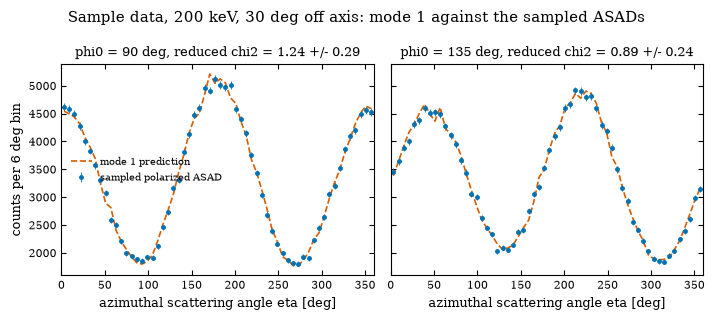

In [ ]:
sample = CsvAdapter(SAMPLE)
ENERGY_1 = 200.0
unp = sample.load_unpolarized(ENERGY_1)
eta = unp.bin_centers

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2), sharey=True)
for ax, phi0 in zip(axes, (90.0, 135.0)):
    pred, pred_err = build_single(unp.counts, unp.bin_edges, ENERGY_1, SAMPLE_DELTA,
                                  SAMPLE_LAMBDA, phi0, GATE, errors=unp.errors)
    truth = sample.load_polarized(ENERGY_1, phi0)
    chi2, chi2_err, nu = calculate_reduced_chi_squared(truth.counts, truth.errors,
                                                       pred, pred_err, norm=1.0)
    ax.errorbar(eta, truth.counts, yerr=truth.errors, fmt=palette.mk("reference"), ms=2.5,
                lw=0.6, color=palette.c("reference"), label="sampled polarized ASAD")
    ax.plot(eta, pred, color=palette.c("mode1"), ls=palette.ls("mode1"), lw=1.2,
            label="mode 1 prediction")
    ax.set_title(f"phi0 = {phi0:.0f} deg, reduced chi2 = {chi2:.2f} +/- {chi2_err:.2f}")
    ax.set_xlim(0, 360)
    ax.set_xlabel("azimuthal scattering angle eta [deg]")
    print(f"phi0 = {phi0:5.1f} deg: reduced chi2 = {chi2:.3f} +/- {chi2_err:.3f} over {nu} bins")
axes[0].set_ylabel("counts per 6 deg bin")
axes[0].legend(frameon=False)
fig.suptitle(f"Sample data, {ENERGY_1:.0f} keV, 30 deg off axis: mode 1 against the sampled ASADs")
fig.tight_layout()
plt.show()
# Caption: for an ideal detector mode 1 is exact, so the two Poisson-sampled
# ASADs of the same beam agree at the statistical level and the reduced
# chi-squared sits near one.


## Any number of angles

The angle list is free. Below the same single unpolarized input produces predictions on a one-degree list of all 181 angles from 0 to 180, shown at once as an image: one row per requested angle. This figure exists for this notebook only (there is no paper counterpart); it uses the same 200 keV, geometry and gate as above, on the sample data.

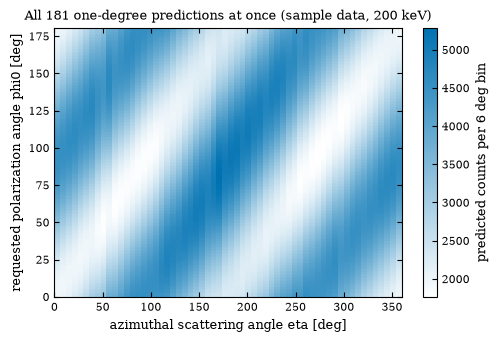

In [ ]:
fine_angles = np.arange(0.0, 181.0, 1.0)
stack = np.zeros((len(fine_angles), len(eta)))
for k, phi0 in enumerate(fine_angles):
    stack[k], _ = build_single(unp.counts, unp.bin_edges, ENERGY_1, SAMPLE_DELTA,
                               SAMPLE_LAMBDA, float(phi0), GATE, errors=unp.errors)

fig, ax = plt.subplots(figsize=(5.6, 3.5))
im = ax.pcolormesh(eta, fine_angles, stack, shading="nearest", cmap=palette.sequential_cmap())
fig.colorbar(im, ax=ax, label="predicted counts per 6 deg bin")
ax.set_xlabel("azimuthal scattering angle eta [deg]")
ax.set_ylabel("requested polarization angle phi0 [deg]")
ax.set_title("All 181 one-degree predictions at once (sample data, 200 keV)")
plt.show()
# Caption: each row of the image is one predicted ASAD from the same
# single unpolarized input, on a single-signed white-to-blue scale. The
# dark band drifting across the image is the modulation peak moving with
# the requested angle; any angle list, however fine, is available this way.


## Part two: the same recipe on a POLAR file

The ROOT adapter reads the POLAR layout (`sim_{energy:03d}_{pol:03d}_{angle:03d}` histograms); `norm_factor` attaches the Poisson errors of the normalized contents. The worked energy is 150 keV, matching the single-ASAD comparison figure of the accompanying paper, with the same source direction and threshold gate; the GEANT4 polarized ASADs at four angles are the ground truth.

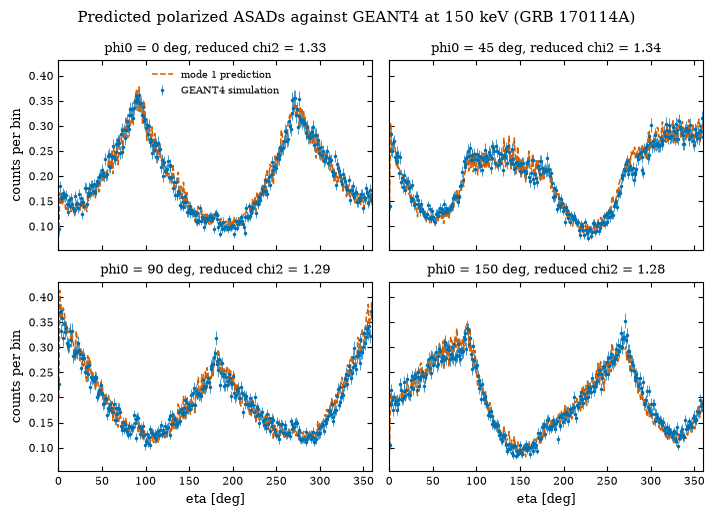

In [ ]:
polar = PolarRootAdapter(POLAR_FILE, norm_factor=NORM_FACTOR)
ENERGY_2 = 150.0
unp_polar = polar.load_unpolarized(ENERGY_2)
eta_polar = unp_polar.bin_centers

angles = (0.0, 45.0, 90.0, 150.0)
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.2), sharex=True, sharey=True)
for ax, phi0 in zip(axes.ravel(), angles):
    pred, pred_err = build_single(unp_polar.counts, unp_polar.bin_edges, ENERGY_2, DELTA,
                                  LAMBDA, phi0, GATE, errors=unp_polar.errors)
    sim = polar.load_polarized(ENERGY_2, phi0)
    chi2, chi2_err, _ = calculate_reduced_chi_squared(sim.counts, sim.errors, pred, pred_err,
                                                      norm=NORM_FACTOR)
    ax.errorbar(eta_polar, sim.counts, yerr=sim.errors, fmt=palette.mk("reference"), ms=1.5,
                lw=0.5, color=palette.c("reference"), label="GEANT4 simulation")
    ax.plot(eta_polar, pred, lw=1.1, color=palette.c("mode1"), ls=palette.ls("mode1"),
            label="mode 1 prediction")
    ax.set_title(f"phi0 = {phi0:.0f} deg, reduced chi2 = {chi2:.2f}")
    ax.set_xlim(0, 360)
axes[0, 0].legend(frameon=False)
for ax in axes[-1]:
    ax.set_xlabel("eta [deg]")
for ax in axes[:, 0]:
    ax.set_ylabel("counts per bin")
fig.suptitle("Predicted polarized ASADs against GEANT4 at 150 keV (GRB 170114A)")
fig.tight_layout()
plt.show()
# Caption: each panel compares the prediction from the single unpolarized
# input (dashed line) against the independently simulated polarized ASAD
# (points) at one polarization angle, at the energy, geometry and gate
# of the paper's comparison figure.
